In [39]:

import os
import json
import uuid
from pathlib import Path

#pour cv et docx
import fitz
from docx import Document
from dotenv import load_dotenv


from openai import OpenAI
from pydantic import BaseModel, Field
from IPython.display import display, Image
from langchain_openai import ChatOpenAI

from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver
from typing import TypedDict

# Charger .env
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

load_dotenv(PROJECT_ROOT / ".env")

api_key = os.getenv("OPENROUTER_API_KEY_1")
assert api_key, "OPENROUTER_API_KEY_1 manquante dans .env"

client = OpenAI(
    api_key=api_key,
    base_url=os.getenv(
        "OPENROUTER_BASE_URL",
        "https://openrouter.ai/api/v1"
    )
)

MODEL = os.getenv("OPENROUTER_MODEL", "openrouter/free")

print("Configuration OK")


Configuration OK


In [40]:
#Graph state 
class CandidateState(TypedDict, total=False):
    cv_path: str
    cv_text: str
    preferences: dict

    candidate_profile: dict
    is_valid: bool


    missing_information: list[str]
    additional_information: dict


In [41]:

# Candidate Profile Schema

class CandidateProfile(BaseModel):
    full_name: str | None = None
    email: str | None = None
    phone: str | None = None
    location: str | None = None

    skills: list[str] = Field(default_factory=list)
    education: list[str] = Field(default_factory=list)
    experience: list[str] = Field(default_factory=list)
    languages: list[str] = Field(default_factory=list)

    target_roles: list[str] = Field(default_factory=list)
    employment_types: list[str] = Field(default_factory=list)


In [50]:
# LLM configuration with structured output

llm = ChatOpenAI(
    model=MODEL,
    api_key=api_key,
    base_url="https://openrouter.ai/api/v1",
    temperature=0
)

structured_llm = llm.with_structured_output(
    CandidateProfile,
    method="function_calling"
)

In [43]:
#test de la classe CandidateProfile
profile = CandidateProfile(
    full_name="Alex Martin",
    email="alex@example.com",
    skills=["Python", "Java", "SQL"],
    target_roles=["Backend Developer"],
    employment_types=["internship"]
)

print(profile.model_dump_json(indent=2))

{
  "full_name": "Alex Martin",
  "email": "alex@example.com",
  "phone": null,
  "location": null,
  "skills": [
    "Python",
    "Java",
    "SQL"
  ],
  "education": [],
  "experience": [],
  "languages": [],
  "target_roles": [
    "Backend Developer"
  ],
  "employment_types": [
    "internship"
  ]
}


In [44]:

# Node 1 : Parse CV

def parse_cv(state: CandidateState) -> dict:
    # Cette fonction extrait le texte du CV (PDF ou DOCX) à partir du chemin fourni dans le State.
    # Elle retourne le texte extrait dans le champ cv_text pour le rendre accessible aux prochains nœuds.

    cv_path = Path(state["cv_path"])

    if not cv_path.is_file():
        raise FileNotFoundError(f"CV introuvable : {cv_path}")

    if cv_path.suffix.lower() == ".pdf":
        with fitz.open(cv_path) as doc:
            cv_text = "\n".join(
                page.get_text("text") for page in doc
            )

    elif cv_path.suffix.lower() == ".docx":
        doc = Document(cv_path)
        cv_text = "\n".join(
            paragraph.text for paragraph in doc.paragraphs
        )

    else:
        raise ValueError("Format non supporté : PDF ou DOCX uniquement.")

    cv_text = cv_text.strip()

    if not cv_text:
        raise ValueError("Aucun texte extrait du CV.")

    return {"cv_text": cv_text}


In [45]:

test_state = {
    "cv_path": str(PROJECT_ROOT / "data" / "cvs" / "MyCv.pdf"),
    "preferences": {
        "employment_types": ["internship"],
        "target_roles": ["Backend AI Developer"]
    }}

result = parse_cv(test_state)

print("Extraction réussie !")
print("Nombre de caractères :", len(result["cv_text"]))
print("\nAperçu du CV :\n")
print(result["cv_text"][:1500])


Extraction réussie !
Nombre de caractères : 3268

Aperçu du CV :

Mohamed Amine Zeaibi
+216 95269015 | mohamed.amine.zeaibi@gmail.com | LinkedIn | GitHub
Summary
AI Software Engineering student ranked Major of Promotion, building backend systems that are cloud-native,
automatically deployed, and AI-augmented. Experienced in Spring Boot, Docker/Kubernetes, and LLM
integration — seeking an internship or part time job to ship intelligent, production-ready applications at scale.
Education
Faculty of Science of Tunis (FST)
Tunisia
TOP 5 - Software Engineering Degree – 2nd Year
Sep 2025 – June 2028
Major of Promotion – Integrated Preparatory Cycle
Sep 2023 – Jun 2025
Experience
Fullstack AI Intern – Tritux Group
Jun 2026 – Jul 2026 (2 months)
• Designed and developed a fullstack application using React and Spring Boot, integrating an AI agent and
implementing a real-time augmented reality try-on feature for eyeglasses selected by the client — shipped to
production.
AI & Backend Developer – D

In [46]:

# Node 2 : Build Candidate Profile

def build_profile(state: CandidateState) -> dict:
    # Analyse le texte du CV avec un LLM configuré pour produire un objet CandidateProfile.
    # Ajoute le profil structuré et validé au State LangGraph.

    cv_text = state["cv_text"]
    preferences = state.get("preferences", {})

    prompt = f"""
    Analyse ce CV et construis le profil du candidat.

    CV :
    {cv_text}

    Préférences :
    {json.dumps(preferences, ensure_ascii=False)}

    Instructions :
    - Extrais uniquement les informations présentes dans le CV.
    - N'invente aucune compétence, expérience ou formation.
    - Utilise null ou des listes vides pour les informations absentes.
    - La localisation du candidat doit venir du CV.
    - Les postes et types d'emploi recherchés viennent des préférences.
    """

    profile = structured_llm.invoke(prompt)

    # Les préférences sont la source de vérité
    profile.target_roles = preferences.get("target_roles", [])
    profile.employment_types = preferences.get("employment_types", [])

    return {
        "candidate_profile": profile.model_dump()
    }


In [51]:

# Test du nœud Build Candidate Profile

state_for_profile = {
    **test_state,
    **result
}

profile_result = build_profile(state_for_profile)

print(json.dumps(
    profile_result["candidate_profile"],
    indent=2,
    ensure_ascii=False
))


{
  "full_name": "Mohamed Amine Zeaibi",
  "email": "mohamed.amine.zeaibi@gmail.com",
  "phone": "+216 95269015",
  "location": "Tunisia",
  "skills": [
    "Python",
    "Java",
    "C++",
    "JavaScript",
    "SQL",
    "T-SQL",
    "PostgreSQL",
    "MySQL",
    "MongoDB",
    "React",
    "Angular",
    "Spring Boot",
    "Spring Security",
    "JWT",
    "OAuth2",
    "Spring AI"
  ],
  "education": [
    "Faculty of Science of Tunis (FST) - TOP 5 - Software Engineering Degree – 2nd Year (Sep 2025 – June 2028)",
    "Major of Promotion – Integrated Preparatory Cycle (Sep 2023 – Jun 2025)"
  ],
  "experience": [
    "Fullstack AI Intern – Tritux Group (Jun 2026 – Jul 2026): Designed and developed a fullstack application using React and Spring Boot, integrating an AI agent and implementing a real-time augmented reality try-on feature for eyeglasses selected by the client — shipped to production.",
    "AI & Backend Developer – DATALIA France (Apr 2026 – Jun 2026): Engineered an adv

In [52]:

# Node 3 : Validate Candidate Profile

def validate_profile(state: CandidateState) -> dict:
    # Vérifie si le profil candidat contient les informations obligatoires.
    # Identifie les informations manquantes et indique si le profil est valide.

    profile = state["candidate_profile"]

    required_fields = [
        "full_name",
        "email",
        "skills",
        "target_roles",
        "employment_types"
    ]

    missing = [
        field for field in required_fields
        if not profile.get(field)
    ]

    return {
        "is_valid": len(missing) == 0,
        "missing_information": missing
    }


In [53]:

# Test du nœud Validate Candidate Profile

state_for_validation = {
    **state_for_profile,
    **profile_result
}

validation_result = validate_profile(state_for_validation)

print("Profil valide :", validation_result["is_valid"])
print("Informations manquantes :", validation_result["missing_information"])


Profil valide : True
Informations manquantes : []


In [54]:

# Node 4 : Ask Missing Information

def ask_missing_info(state: CandidateState) -> dict:
    # Interrompt le graphe pour demander à l'utilisateur les informations manquantes.
    # Intègre les réponses dans le profil candidat avant de reprendre le workflow.

    missing = state["missing_information"]

    answers = interrupt({
        "message": "Veuillez compléter les informations manquantes.",
        "missing_fields": missing
    })

    profile = state["candidate_profile"].copy()

    for field in missing:
        if field in answers:
            profile[field] = answers[field]

    profile = CandidateProfile.model_validate(profile)

    return {
        "candidate_profile": profile.model_dump(),
        "additional_information": answers
    }


In [55]:

# Build Candidate Profile Graph

def route_validation(state: CandidateState) -> str:
    return "valid" if state["is_valid"] else "missing"


graph_builder = StateGraph(CandidateState)

# Ajouter les nœuds
graph_builder.add_node("parse_cv", parse_cv)
graph_builder.add_node("build_profile", build_profile)
graph_builder.add_node("validate_profile", validate_profile)
graph_builder.add_node("ask_missing_info", ask_missing_info)

# Définir le chemin principal
graph_builder.add_edge(START, "parse_cv")
graph_builder.add_edge("parse_cv", "build_profile")
graph_builder.add_edge("build_profile", "validate_profile")

# Choisir le chemin selon la validation
graph_builder.add_conditional_edges(
    "validate_profile",
    route_validation,
    {
        "valid": END,
        "missing": "ask_missing_info"
    }
)

# Revalider après avoir complété le profil
graph_builder.add_edge("ask_missing_info", "validate_profile")

# Permettre la reprise après interrupt()
checkpointer = InMemorySaver()

candidate_graph = graph_builder.compile(
    checkpointer=checkpointer
)

print("Candidate Profile Graph compilé avec succès !")


Candidate Profile Graph compilé avec succès !


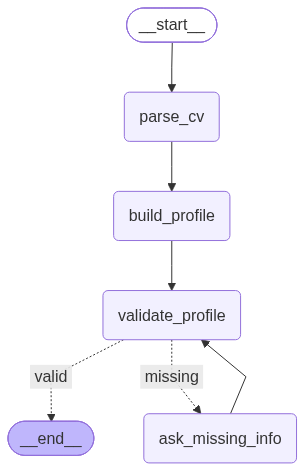

In [56]:
candidate_graph 

In [57]:

# Test du graphe complet avec le CV et les préférences du candidat

initial_state = {
    "cv_path": str(PROJECT_ROOT / "data" / "cvs" / "MyCv.pdf"),
    "preferences": {
        "employment_types": ["internship"],
        "target_roles": ["Backend AI Developer"]
    }
}

config = {
    "configurable": {
        "thread_id": str(uuid.uuid4())
    }
}

final_state = candidate_graph.invoke(
    initial_state,
    config=config
)

print("=== RÉSULTAT DU GRAPHE ===")
print("Profil valide :", final_state.get("is_valid"))
print("Informations manquantes :", final_state.get("missing_information"))

print("\n=== PROFIL CANDIDAT ===")
print(json.dumps(
    final_state.get("candidate_profile", {}),
    indent=2,
    ensure_ascii=False
))


=== RÉSULTAT DU GRAPHE ===
Profil valide : True
Informations manquantes : []

=== PROFIL CANDIDAT ===
{
  "full_name": "Mohamed Amine Zeaibi",
  "email": "mohamed.amine.zeaibi@gmail.com",
  "phone": "+216 95269015",
  "location": "Tunisia",
  "skills": [
    "Python",
    "Java",
    "C++",
    "JavaScript",
    "SQL",
    "T-SQL",
    "PostgreSQL",
    "MySQL",
    "MongoDB",
    "React",
    "Angular",
    "Spring Boot",
    "Spring Security",
    "JWT",
    "OAuth2",
    "Spring AI",
    "WebSocket",
    "Microservices",
    "Kafka",
    "Machine Learning",
    "RAG",
    "Agentic AI",
    "LangChain",
    "LangGraph",
    "LangSmith",
    "Docker",
    "Kubernetes",
    "Git",
    "GitHub",
    "Linux (Ubuntu)",
    "Prometheus",
    "Grafana",
    "IBM Java Developer",
    "IBM AI Engineering Professional",
    "IBM RAG and Agentic AI",
    "AWS Cloud Practitioner"
  ],
  "education": [
    "Faculty of Science of Tunis (FST) - TOP 5 - Software Engineering Degree – 2nd Year (Sep 20

In [59]:

# Test du mécanisme interrupt() avec des préférences manquantes

incomplete_state = {
    "cv_path": str(PROJECT_ROOT / "data" / "cvs" / "MyCv.pdf"),
    "preferences": {
        "employment_types": ["internship"],
        "target_roles": []
    }
}

interrupt_config = {
    "configurable": {
        "thread_id": str(uuid.uuid4())
    }
}

interrupt_result = candidate_graph.invoke(
    incomplete_state,
    config=interrupt_config
)

print("=== RÉSULTAT ===")
print("Profil valide :", interrupt_result.get("is_valid"))
print("Informations manquantes :", interrupt_result.get("missing_information"))
print("Interruption :", interrupt_result.get("__interrupt__"))


=== RÉSULTAT ===
Profil valide : False
Informations manquantes : ['target_roles']
Interruption : [Interrupt(value={'message': 'Veuillez compléter les informations manquantes.', 'missing_fields': ['target_roles']}, id='74f241f899220b9c8987cf7f4961c11c', response_schema=None)]


In [60]:

# Test : Resume Candidate Profile Graph

# Reprendre le graphe avec les informations manquantes
resumed_state = candidate_graph.invoke(
    Command(
        resume={
            "target_roles": ["Backend AI Developer"]
        }
    ),
    config=interrupt_config
)

print("=== RÉSULTAT APRÈS REPRISE ===")
print("Profil valide :", resumed_state.get("is_valid"))
print("Informations manquantes :", resumed_state.get("missing_information"))
print("Postes recherchés :", resumed_state["candidate_profile"]["target_roles"])
print("Informations ajoutées :", resumed_state.get("additional_information"))


=== RÉSULTAT APRÈS REPRISE ===
Profil valide : True
Informations manquantes : []
Postes recherchés : ['Backend AI Developer']
Informations ajoutées : {'target_roles': ['Backend AI Developer']}


In [61]:

# Afficher le State final du Candidate Profile Graph

final_candidate_state = candidate_graph.get_state(
    interrupt_config
)

print("=== FINAL CANDIDATE STATE ===")
print(json.dumps(
    final_candidate_state.values,
    indent=2,
    ensure_ascii=False
))

print("\nProchains nœuds :", final_candidate_state.next)


=== FINAL CANDIDATE STATE ===
{
  "cv_path": "C:\\Users\\moham\\Desktop\\PFA IGL4\\S1\\Python\\data\\cvs\\MyCv.pdf",
  "cv_text": "Mohamed Amine Zeaibi\n+216 95269015 | mohamed.amine.zeaibi@gmail.com | LinkedIn | GitHub\nSummary\nAI Software Engineering student ranked Major of Promotion, building backend systems that are cloud-native,\nautomatically deployed, and AI-augmented. Experienced in Spring Boot, Docker/Kubernetes, and LLM\nintegration — seeking an internship or part time job to ship intelligent, production-ready applications at scale.\nEducation\nFaculty of Science of Tunis (FST)\nTunisia\nTOP 5 - Software Engineering Degree – 2nd Year\nSep 2025 – June 2028\nMajor of Promotion – Integrated Preparatory Cycle\nSep 2023 – Jun 2025\nExperience\nFullstack AI Intern – Tritux Group\nJun 2026 – Jul 2026 (2 months)\n• Designed and developed a fullstack application using React and Spring Boot, integrating an AI agent and\nimplementing a real-time augmented reality try-on feature for eye